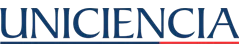

# Selección de aplicaciones y legibilidad de políticas de datos
Estudio documental sobre aplicaciones de registro glucémico en Google Play Colombia.

**Contenido**
1. Instalación y funciones de carga de archivos
2. Corpus de Google Play (descarga con `google-play-scraper` Y carga del Excel ya generado)
3. Limpieza de métricas
4. Selección: puntuación **> 4,0** y **más de 1.000 calificaciones** de usuarios
5. Exclusiones documentadas y verificación contra las filas marcadas en amarillo del Excel
6. Índice Flesch-Szigriszt y tramo INFLESZ (objetivo específico 2)
7. Subida de todas las políticas en un solo paso y resultados por aplicación


# Video: explicación Código Selección De Aplicaciones E Implementación De Indice Índice Flesch-Szigriszt Y Tramo Inflesz

*   https://www.youtube.com/watch?v=go1DBq3NmMQ

# Aplicación de la matriz de criterios

* https://docs.google.com/spreadsheets/d/13hBCNM9ypLzG1FgXfya7Nqy5dfeFlcZSXm6TGItAJMA/edit?usp=sharing





## 1. Instalación y funciones de carga

In [ ]:
!pip install -q google-play-scraper openpyxl

import os
import re
import io
import time
import zipfile
import unicodedata
import xml.etree.ElementTree as ET
from datetime import date

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_colwidth", 60)

# Carpeta de la que se leen los archivos cuando el notebook se ejecuta fuera de Colab
CARPETA_LOCAL = "datos"


def subir_archivos(mensaje, extensiones):
    """Devuelve {nombre: bytes}. En Colab muestra el botón de subida (admite varios archivos);
    fuera de Colab lee los archivos con esas extensiones desde CARPETA_LOCAL
    (ignora los archivos salida_* que genera este notebook)."""
    try:
        from google.colab import files
        print(mensaje)
        subidos = files.upload()
    except ImportError:
        subidos = {}
        for nombre in sorted(os.listdir(CARPETA_LOCAL)):
            if nombre.lower().endswith(extensiones) and not nombre.startswith("salida_"):
                with open(os.path.join(CARPETA_LOCAL, nombre), "rb") as f:
                    subidos[nombre] = f.read()
        print(f"Leídos desde '{CARPETA_LOCAL}': {list(subidos)}")
    return {n: c for n, c in subidos.items() if n.lower().endswith(extensiones)}


def descargar(ruta):
    try:
        from google.colab import files
        files.download(ruta)
    except ImportError:
        print("Archivo guardado en:", os.path.abspath(ruta))


def clave(texto):
    """Normaliza un nombre para comparar títulos con nombres de archivo:
    decodifica #U00fa, quita tildes, símbolos y espacios."""
    texto = re.sub(r"#U([0-9a-fA-F]{4})", lambda m: chr(int(m.group(1), 16)), str(texto))
    texto = unicodedata.normalize("NFKD", texto)
    texto = "".join(c for c in texto if not unicodedata.combining(c))
    return re.sub(r"[^a-z0-9]", "", texto.lower())

print("Listo.")

## 2. Corpus de Google Play Colombia
Por defecto se usa el Excel ya generado (`Seleccion_Applicaciones_play_colombia.xlsx`), porque es la foto del corpus que se documenta en la monografía. Si `EJECUTAR_SCRAPING = True`, se vuelve a descargar todo desde Google Play; las cifras cambiarán respecto a la fecha de la consulta original.

In [ ]:
EJECUTAR_SCRAPING = False

TERMINOS = ["glucosa", "registro de glucosa", "diabetes control",
            "azúcar en sangre", "glucemia"]
PAIS, IDIOMA = "co", "es"

# Si Colombia no devuelve métricas, se prueba en este orden.
# La primera siempre es Colombia; las demás solo rellenan huecos.
LOCALES_RESPALDO = [("co", "es"), ("mx", "es"), ("us", "es"), ("us", "en")]
METRICAS = ["ratings", "reviews", "score"]


def ficha(app_id, pais, idioma, intentos=3):
    """Descarga la ficha con reintentos (Play a veces corta por exceso de peticiones)."""
    from google_play_scraper import app
    for i in range(intentos):
        try:
            return app(app_id, lang=idioma, country=pais)
        except Exception:
            if i == intentos - 1:
                raise
            time.sleep(2 * (i + 1))


def metricas_completas(d):
    return all(d.get(m) is not None for m in METRICAS)


def descargar_corpus():
    from google_play_scraper import search

    # 1. Búsqueda: reúne candidatos sin duplicados
    candidatos = {}
    for termino in TERMINOS:
        for r in search(termino, lang=IDIOMA, country=PAIS, n_hits=30):
            candidatos.setdefault(r["appId"], []).append(termino)
        time.sleep(1)
    print(f"Candidatos únicos tras la búsqueda: {len(candidatos)}")

    # 2. Ficha completa de cada candidato
    filas = []
    for app_id, terminos in candidatos.items():
        try:
            d = ficha(app_id, PAIS, IDIOMA)
        except Exception as e:
            print(f"  omitida {app_id}: {e}")
            continue

        # 2b. Si faltan métricas, buscarlas en otros países/idiomas
        origen = f"{PAIS}-{IDIOMA}" if metricas_completas(d) else None
        if origen is None:
            for pais_r, idioma_r in LOCALES_RESPALDO[1:]:
                try:
                    d_r = ficha(app_id, pais_r, idioma_r)
                except Exception:
                    continue
                if metricas_completas(d_r):
                    for m in METRICAS:
                        d[m] = d_r[m]
                    origen = f"{pais_r}-{idioma_r}"
                    break
                time.sleep(1)
            if origen is None:
                origen = "sin_datos"

        filas.append({
            "titulo": d["title"],
            "appId": app_id,
            "desarrollador": d["developer"],
            "instalaciones_texto": d["installs"],
            "min_instalaciones": d["minInstalls"],
            "instalaciones_reales": d.get("realInstalls"),
            "calificaciones": d["ratings"],
            "resenas": d["reviews"],
            "puntuacion": d["score"],
            "origen_metricas": origen,
            "gratuita": d["free"],
            "version": d["version"],
            "ultima_actualizacion": d["lastUpdatedOn"],
            "politica_privacidad": d.get("privacyPolicy"),
            "categoria": d["genre"],
            "url": f"https://play.google.com/store/apps/details?id={app_id}",
            "terminos_que_la_arrojaron": " | ".join(sorted(set(terminos))),
            "fecha_consulta": date.today().isoformat(),
        })
        time.sleep(1)

    return (pd.DataFrame(filas)
              .sort_values(["instalaciones_reales", "calificaciones"],
                           ascending=False, na_position="last")
              .reset_index(drop=True))


marcadas_amarillo = set()   # appIds resaltados en amarillo en el Excel (selección manual previa)

if EJECUTAR_SCRAPING:
    corpus = descargar_corpus()
    corpus.to_csv("corpus_play_colombia.csv", index=False, encoding="utf-8-sig")
else:
    from openpyxl import load_workbook
    archivo = subir_archivos("Suba el Excel del corpus (Seleccion_Applicaciones_play_colombia.xlsx):",
                             (".xlsx",))
    nombre, contenido = next(iter(archivo.items()))
    corpus = pd.read_excel(io.BytesIO(contenido))

    # Lee el color de relleno de cada fila para comparar después con la selección automática
    hoja = load_workbook(io.BytesIO(contenido)).active
    col_id = [c.value for c in hoja[1]].index("appId") + 1
    for fila in range(2, hoja.max_row + 1):
        relleno = hoja.cell(fila, 1).fill
        if relleno.fill_type and relleno.fgColor.rgb == "FFFFFF00":
            marcadas_amarillo.add(hoja.cell(fila, col_id).value)

print(f"Aplicaciones en el corpus: {len(corpus)}")
print(f"Filas marcadas en amarillo en el Excel: {len(marcadas_amarillo)}")
display(corpus[["titulo", "calificaciones", "puntuacion", "instalaciones_texto", "origen_metricas"]].head(10))

Suba el Excel del corpus (Seleccion_Applicaciones_play_colombia.xlsx):


Saving Seleccion_Applicaciones_play_colombia.xlsx to Seleccion_Applicaciones_play_colombia.xlsx
Aplicaciones en el corpus: 56
Filas marcadas en amarillo en el Excel: 15


,titulo,calificaciones,puntuacion,instalaciones_texto,origen_metricas
0,Glucemia - Diabetes App,64494.0,4.764151,10.000.000+,co-es
1,Presión arterial y azúcar,20845.0,4.411765,10.000.000+,co-es
2,mySugr - Diario para diabetes,142358.0,4.800000,5.000.000+,co-es
3,Azúcar en Sangre - BP Tracker,NaN,NaN,5.000.000+,sin_datos
4,Glucosa y Presión: iCardio,8011.0,4.712871,1.000.000+,co-es
5,BeatO: Diabetes Care App,46010.0,4.280000,1.000.000+,us-es
6,Blood Sugar & BP Tracker,9893.0,4.701492,1.000.000+,co-es
7,Blood Sugar & Diabetes Tracker,387.0,2.000000,1.000.000+,mx-es
8,Diabetes: Azúcar en la Sangre,6832.0,4.382022,1.000.000+,co-es
9,Diabetes:M - Blood Sugar Diary,24029.0,4.830000,500.000+,co-es


## 3. Limpieza de métricas
Excel guardó algunas cifras como texto (`'64494.0'`) y en al menos un caso perdió el separador decimal de la puntuación (`4825` en lugar de `4,825`). Una puntuación de Google Play nunca supera 5, así que cualquier valor mayor se divide entre 10 hasta quedar en la escala 1–5.

In [ ]:
def corregir_puntuacion(valor):
    if pd.isna(valor):
        return valor
    while valor > 5:
        valor = valor / 10
    return valor

for col in ["calificaciones", "resenas", "instalaciones_reales"]:
    corpus[col] = pd.to_numeric(corpus[col], errors="coerce")

puntuacion_original = pd.to_numeric(corpus["puntuacion"], errors="coerce")
corpus["puntuacion"] = puntuacion_original.apply(corregir_puntuacion)

corregidas = corpus[puntuacion_original != corpus["puntuacion"]].dropna(subset=["puntuacion"])
if len(corregidas):
    print("Puntuaciones corregidas por pérdida del decimal:")
    for i in corregidas.index:
        print(f"  {corpus.loc[i, 'titulo']}: {puntuacion_original[i]} -> {corpus.loc[i, 'puntuacion']}")

Puntuaciones corregidas por pérdida del decimal:
  Diario de azúcar para diabetes: 4825.0 -> 4.825


## 4. Selección por popularidad y valoración
Regla de descarte: se conserva la aplicación solo si su puntuación es **mayor que 4,0** y tiene **más de 1.000 calificaciones** hechas por usuarios. Las apps sin métricas en ningún país (`sin_datos`) quedan descartadas porque no se pueden verificar.

In [ ]:
UMBRAL_PUNTUACION = 4.0
UMBRAL_CALIFICACIONES = 1000


def motivo_descarte(fila):
    if pd.isna(fila["puntuacion"]) or pd.isna(fila["calificaciones"]):
        return "Sin métricas en Google Play"
    motivos = []
    if fila["puntuacion"] <= UMBRAL_PUNTUACION:
        motivos.append(f"Puntuación ≤ {UMBRAL_PUNTUACION}")
    if fila["calificaciones"] <= UMBRAL_CALIFICACIONES:
        motivos.append(f"≤ {UMBRAL_CALIFICACIONES} calificaciones")
    return " y ".join(motivos)


corpus["motivo_descarte"] = corpus.apply(motivo_descarte, axis=1)
corpus["cumple_filtro"] = corpus["motivo_descarte"] == ""

print(f"Corpus inicial: {len(corpus)}")
print(f"Cumplen el filtro: {corpus['cumple_filtro'].sum()}")
print("\nDescartes por motivo:")
print(corpus.loc[~corpus["cumple_filtro"], "motivo_descarte"].value_counts().to_string())

Corpus inicial: 56
Cumplen el filtro: 17

Descartes por motivo:
motivo_descarte
Sin métricas en Google Play                 21
≤ 1000 calificaciones                       10
Puntuación ≤ 4.0 y ≤ 1000 calificaciones     6
Puntuación ≤ 4.0                             2


## 5. Exclusiones documentadas y selección final
Algunas apps pasan el filtro numérico pero no corresponden al objeto de estudio (apps de registro glucémico). Se excluyen aquí, cada una con su motivo, para que la decisión quede trazable. La celda compara el resultado con las filas que estaban en amarillo en el Excel.

In [ ]:
EXCLUSIONES = {
    "com.rfit.glycemicindextracker": "Consulta de índice glucémico de alimentos; no registra glucemia",
    "com.medm.medmbg.diary": "PENDIENTE: escribir el motivo de exclusión",
}

corpus["exclusion_manual"] = corpus["appId"].map(EXCLUSIONES).fillna("")
corpus["seleccionada"] = corpus["cumple_filtro"] & (corpus["exclusion_manual"] == "")
corpus.loc[corpus["cumple_filtro"] & ~corpus["seleccionada"], "motivo_descarte"] = \
    "Exclusión: " + corpus["exclusion_manual"]

seleccion = corpus[corpus["seleccionada"]].reset_index(drop=True)
seleccion.index = seleccion.index + 1

print(f"Selección final: {len(seleccion)} aplicaciones\n")
display(seleccion[["titulo", "desarrollador", "calificaciones", "puntuacion",
                   "instalaciones_texto", "origen_metricas"]])

# Verificación contra el resaltado amarillo del Excel
if marcadas_amarillo:
    ids_sel = set(seleccion["appId"])
    solo_filtro = ids_sel - marcadas_amarillo
    solo_amarillo = marcadas_amarillo - ids_sel
    if not solo_filtro and not solo_amarillo:
        print("✔ La selección coincide exactamente con las filas marcadas en amarillo.")
    else:
        for i in solo_filtro:
            print("Seleccionada pero no está en amarillo:", corpus.loc[corpus.appId == i, "titulo"].iloc[0])
        for i in solo_amarillo:
            print("En amarillo pero no seleccionada:", corpus.loc[corpus.appId == i, "titulo"].iloc[0])

Selección final: 15 aplicaciones



,titulo,desarrollador,calificaciones,puntuacion,instalaciones_texto,origen_metricas
1,Glucemia - Diabetes App,QR Code Scanner.,64494.0,4.764151,10.000.000+,co-es
2,Presión arterial y azúcar,HealthTracker Apps,20845.0,4.411765,10.000.000+,co-es
3,mySugr - Diario para diabetes,mySugr GmbH,142358.0,4.800000,5.000.000+,co-es
4,Glucosa y Presión: iCardio,CodeJoy,8011.0,4.712871,1.000.000+,co-es
5,BeatO: Diabetes Care App,BeatO,46010.0,4.280000,1.000.000+,us-es
6,Blood Sugar & BP Tracker,Oxylab Studio,9893.0,4.701492,1.000.000+,co-es
7,Diabetes: Azúcar en la Sangre,mEL Studio,6832.0,4.382022,1.000.000+,co-es
8,Diabetes:M - Blood Sugar Diary,Sirma Medical Systems,24029.0,4.830000,500.000+,co-es
9,Control de la Glucosa,Lehreer SAS,4109.0,4.460000,500.000+,co-es
10,DiabTrend: Diario de Diabetes,DiabTrend AI Analytics Inc.,2238.0,4.400000,100.000+,co-es


✔ La selección coincide exactamente con las filas marcadas en amarillo.


In [ ]:
# Exportar el corpus con la decisión de cada app; las seleccionadas quedan en amarillo
from openpyxl.styles import PatternFill

nombre_xlsx = "salida_seleccion_aplicaciones.xlsx"
salida = corpus.drop(columns=["exclusion_manual"])
salida.to_excel(nombre_xlsx, index=False)

from openpyxl import load_workbook
libro = load_workbook(nombre_xlsx)
hoja = libro.active
amarillo = PatternFill(start_color="FFFF00", end_color="FFFF00", fill_type="solid")
for fila, elegida in enumerate(salida["seleccionada"], start=2):
    if elegida:
        for celda in hoja[fila]:
            celda.fill = amarillo
libro.save(nombre_xlsx)
descargar(nombre_xlsx)

## 6. Índice Flesch-Szigriszt y tramo INFLESZ
**Fórmula (Szigriszt-Pazos, 1993):** IFSZ = 206,835 − 62,3 × (sílabas / palabras) − (palabras / frases)

**Escala INFLESZ (Barrio-Cantalejo et al., 2008):**

| IFSZ | Tramo |
|---|---|
| < 40 | Muy difícil |
| 40 – 55 | Algo difícil |
| 55 – 65 | Normal |
| 65 – 80 | Bastante fácil |
| > 80 | Muy fácil |

In [ ]:
VOCALES_FUERTES = set("aeoáéó")
VOCALES_DEBILES = set("iuü")
DEBILES_TILDADAS = set("íú")
VOCALES = VOCALES_FUERTES | VOCALES_DEBILES | DEBILES_TILDADAS

# Abreviaturas frecuentes en textos legales que terminan en punto y no cierran frase
ABREVIATURAS = {
    "art", "arts", "núm", "num", "no", "nro", "pág", "págs", "sr", "sra", "srs",
    "dr", "dra", "etc", "ej", "p", "pp", "inc", "lit", "cap", "vol",
    "s.a", "s.a.s", "ltda", "cía", "co", "av", "cra", "cl", "tel", "ext",
    "aprox", "máx", "mín", "dto", "decr", "res", "e.g", "i.e", "vs", "ud", "uds",
}

PALABRAS_FUNCIONALES_ES = {
    "de", "la", "que", "el", "en", "y", "los", "se", "del", "las", "por", "un",
    "para", "con", "una", "su", "al", "lo", "como", "más", "o", "sus", "datos",
}


def limpiar_texto(texto):
    """Normaliza el texto y elimina elementos que distorsionan el conteo."""
    texto = unicodedata.normalize("NFC", texto)
    texto = re.sub(r"(?:https?://|www\.)\S+?(?=[.,;:)]?(?:\s|$))", " ", texto)  # URLs
    texto = re.sub(r"[\w.+-]+@[\w-]+(?:\.[\w-]+)+", " ", texto)                 # correos
    texto = re.sub(r"(\d)\.(\d)", r"\1\2", texto)                                # 1.581 -> 1581
    texto = re.sub(r"[ \t]+", " ", texto)
    return texto.strip()


def contar_frases(texto):
    """Segmentos terminados en . ! ? … o en salto de línea
    (los títulos y viñetas sin punto final cuentan como frase)."""
    def proteger(m):
        palabra = m.group(1)
        if palabra.lower().rstrip(".") in ABREVIATURAS or len(palabra) == 1:
            return palabra.replace(".", "§") + "§"
        return m.group(0)

    t = re.sub(r"\b([A-Za-zÁÉÍÓÚáéíóúÑñ]+(?:\.[A-Za-z]+)*)\.(?=\s+[a-záéíóúñ0-9(])",
               proteger, texto)
    segmentos = re.split(r"[.!?…]+|\n+", t)
    return sum(1 for s in segmentos if re.search(r"[A-Za-zÁÉÍÓÚáéíóúÑñÜü]", s))


def extraer_palabras(texto):
    """Palabras = secuencias con al menos una letra (se excluyen cifras y símbolos)."""
    return re.findall(r"[A-Za-zÁÉÍÓÚáéíóúÑñÜü]+", texto)


def silabas_palabra(palabra):
    """Cuenta sílabas por núcleos vocálicos:
    - Diptongo: fuerte + débil átona, débil átona + fuerte, débil + débil -> 1 sílaba.
    - Hiato: fuerte + fuerte, o vocal junto a í/ú tildada -> 2 sílabas.
    - 'y' es vocal al final de palabra o ante consonante (hoy, muy, y)."""
    p = palabra.lower()
    letras = []
    for i, ch in enumerate(p):
        if ch == "y":
            siguiente = p[i + 1] if i + 1 < len(p) else ""
            letras.append("i" if siguiente not in VOCALES else "y")
        else:
            letras.append(ch)

    silabas = 0
    i = 0
    while i < len(letras):
        if letras[i] in VOCALES:
            grupo = [letras[i]]
            j = i + 1
            while j < len(letras) and letras[j] in VOCALES:
                grupo.append(letras[j])
                j += 1
            nucleos = 1
            for a, b in zip(grupo, grupo[1:]):
                hiato = (a in VOCALES_FUERTES and b in VOCALES_FUERTES) or \
                        (a in DEBILES_TILDADAS or b in DEBILES_TILDADAS)
                if hiato:
                    nucleos += 1
            silabas += nucleos
            i = j
        else:
            i += 1
    return max(silabas, 1)


def tramo_inflesz(ifsz):
    """Mismos límites que la ficha de evaluación en Excel."""
    if ifsz < 40:
        return "Muy difícil"
    if ifsz < 55:
        return "Algo difícil"
    if ifsz < 65:
        return "Normal"
    if ifsz <= 80:
        return "Bastante fácil"
    return "Muy fácil"


def parece_espanol(palabras):
    """Heurística: proporción de palabras funcionales del español."""
    if not palabras:
        return False
    muestra = [w.lower() for w in palabras[:500]]
    return sum(w in PALABRAS_FUNCIONALES_ES for w in muestra) / len(muestra) >= 0.15


def analizar(texto):
    limpio = limpiar_texto(texto)
    palabras = extraer_palabras(limpio)
    if not palabras:
        raise ValueError("El texto no contiene palabras.")
    n_palabras = len(palabras)
    n_frases = max(contar_frases(limpio), 1)
    n_silabas = sum(silabas_palabra(w) for w in palabras)
    ifsz = 206.835 - 62.3 * (n_silabas / n_palabras) - (n_palabras / n_frases)
    return {
        "palabras": n_palabras,
        "silabas": n_silabas,
        "frases": n_frases,
        "silabas_por_palabra": round(n_silabas / n_palabras, 2),
        "palabras_por_frase": round(n_palabras / n_frases, 2),
        "ifsz": round(ifsz, 1),
        "tramo": tramo_inflesz(ifsz),
        "espanol": parece_espanol(palabras),
    }


def leer_txt(contenido):
    for cod in ("utf-8-sig", "utf-8", "cp1252", "latin-1"):
        try:
            return contenido.decode(cod)
        except UnicodeDecodeError:
            continue
    raise ValueError("No se pudo decodificar el archivo de texto.")


def leer_docx(contenido):
    """Extrae el texto de un .docx sin librerías externas (un párrafo por línea)."""
    w = "{http://schemas.openxmlformats.org/wordprocessingml/2006/main}"
    with zipfile.ZipFile(io.BytesIO(contenido)) as z:
        raiz = ET.fromstring(z.read("word/document.xml"))
    parrafos = []
    for p in raiz.iter(f"{w}p"):
        partes = []
        for nodo in p.iter():
            if nodo.tag == f"{w}t" and nodo.text:
                partes.append(nodo.text)
            elif nodo.tag == f"{w}tab":
                partes.append(" ")
        linea = "".join(partes).strip()
        if linea:
            parrafos.append(linea)
    return "\n".join(parrafos)


def desempacar(archivos):
    """Convierte lo subido en {nombre_archivo: texto}. Abre los .zip y toma sus .txt/.docx."""
    textos = {}
    for nombre, contenido in archivos.items():
        if nombre.lower().endswith(".zip"):
            with zipfile.ZipFile(io.BytesIO(contenido)) as z:
                internos = {os.path.basename(n): z.read(n) for n in z.namelist()
                            if n.lower().endswith((".txt", ".docx")) and "__MACOSX" not in n}
            textos.update(desempacar(internos))
        elif nombre.lower().endswith(".txt"):
            textos[nombre] = leer_txt(contenido)
        elif nombre.lower().endswith(".docx"):
            textos[nombre] = leer_docx(contenido)
    return textos

print("Funciones de legibilidad cargadas.")

Funciones de legibilidad cargadas.


## 7. Subir todas las políticas y calcular
Suba en un solo paso todos los `.txt` (o `.docx`) de las políticas, o el `.zip` de la carpeta completa. Cada archivo se empareja con la aplicación seleccionada cuyo título coincide con el nombre del archivo (se ignoran tildes, signos y espacios).

In [ ]:
subidos = subir_archivos("Seleccione TODAS las políticas (.txt / .docx) o el .zip de la carpeta:",
                         (".txt", ".docx", ".zip"))
textos = desempacar(subidos)
print(f"Políticas leídas: {len(textos)}")

# Emparejar cada archivo con una app de la selección
claves_apps = {clave(t): t for t in seleccion["titulo"]}

def app_de_archivo(nombre):
    k = clave(os.path.splitext(nombre)[0])
    if k in claves_apps:
        return claves_apps[k]
    for k_app, titulo in claves_apps.items():   # coincidencia parcial
        if k in k_app or k_app in k:
            return titulo
    return None

filas = []
for nombre, texto in textos.items():
    titulo = app_de_archivo(nombre)
    try:
        r = analizar(texto)
        filas.append({
            "titulo": titulo if titulo else "(no emparejada)",
            "Archivo": nombre,
            "Palabras de la política": r["palabras"],
            "Sílabas": r["silabas"],
            "Frases": r["frases"],
            "Sílabas/palabra": r["silabas_por_palabra"],
            "Palabras/frase": r["palabras_por_frase"],
            "Índice Flesch-Szigriszt": r["ifsz"],
            "Tramo INFLESZ": r["tramo"],
            "Observación": "" if r["espanol"] else "No parece español: índice no válido",
        })
    except Exception as e:
        filas.append({"titulo": titulo, "Archivo": nombre, "Observación": f"Error: {e}"})

legibilidad = pd.DataFrame(filas)

# Unir con la selección para ver qué apps quedaron sin política
resultados = (seleccion[["titulo", "desarrollador", "calificaciones", "puntuacion"]]
              .merge(legibilidad, on="titulo", how="outer"))
resultados["Archivo"] = resultados["Archivo"].fillna("— sin política cargada —")
resultados = resultados.sort_values("Índice Flesch-Szigriszt", na_position="last").reset_index(drop=True)
resultados.index = resultados.index + 1

display(resultados[["titulo", "Palabras de la política", "Frases", "Sílabas/palabra",
                    "Palabras/frase", "Índice Flesch-Szigriszt", "Tramo INFLESZ", "Observación"]])

sin_politica = resultados[resultados["Archivo"] == "— sin política cargada —"]["titulo"].tolist()
no_emparejadas = legibilidad[legibilidad["titulo"] == "(no emparejada)"]["Archivo"].tolist()
if sin_politica:
    print("Apps seleccionadas sin política cargada:", sin_politica)
if no_emparejadas:
    print("Archivos que no coinciden con ninguna app seleccionada:", no_emparejadas)

Seleccione TODAS las políticas (.txt / .docx) o el .zip de la carpeta:


Saving BeatO Diabetes Care App.txt to BeatO Diabetes Care App.txt
Saving Blood Sugar & BP Tracker.txt to Blood Sugar & BP Tracker.txt
Saving Control de la Glucosa.txt to Control de la Glucosa.txt
Saving Diabetes Azúcar en la Sangre.txt to Diabetes Azúcar en la Sangre.txt
Saving Diabetes M - Blood Sugar Diary.txt to Diabetes M - Blood Sugar Diary.txt
Saving DiabTrend Diario de Diabetes.txt to DiabTrend Diario de Diabetes.txt
Saving Diario de diabetes.txt to Diario de diabetes.txt
Saving Diario insulina - Diabetes.txt to Diario insulina - Diabetes.txt
Saving Glucemia - Diabetes App.txt to Glucemia - Diabetes App.txt
Saving Glucosa y Presión iCardio.txt to Glucosa y Presión iCardio.txt
Saving Gluroo Registrador de Diabetes.txt to Gluroo Registrador de Diabetes.txt
Saving Gmate® Healthcare.txt to Gmate® Healthcare.txt
Saving MyDiabetes Meal Carb Tracker.txt to MyDiabetes Meal Carb Tracker.txt
Saving mySugr - Diario para diabetes.txt to mySugr - Diario para diabetes.txt
Saving Presión arter

,titulo,Palabras de la política,Frases,Sílabas/palabra,Palabras/frase,Índice Flesch-Szigriszt,Tramo INFLESZ,Observación
1,Presión arterial y azúcar,1472,93,2.45,15.83,38.5,Muy difícil,
2,Gmate® Healthcare,2233,110,2.33,20.30,41.5,Algo difícil,
3,"MyDiabetes: Meal, Carb Tracker",7564,326,2.26,23.20,42.5,Algo difícil,
4,Diabetes:M - Blood Sugar Diary,2083,111,2.33,18.77,43.0,Algo difícil,
5,DiabTrend: Diario de Diabetes,4367,243,2.32,17.97,44.4,Algo difícil,
6,Gluroo Registrador de Diabetes,3334,191,2.29,17.46,46.5,Algo difícil,
7,Control de la Glucosa,1607,120,2.33,13.39,48.3,Algo difícil,
8,Diario insulina - Diabetes,735,77,2.39,9.55,48.4,Algo difícil,
9,Glucosa y Presión: iCardio,579,49,2.35,11.82,48.7,Algo difícil,
10,Diario de diabetes,1183,81,2.30,14.60,49.0,Algo difícil,
